### Principal Component Analysis (PCA) – Mastering Dimensionality Reduction & Visualization

### 1. The High-Dimensional Data Challenge
- High-Dimensionality Problem
    * Datasets in real-world applications (e.g., medical imaging, tumor measurements, sales data, biological measurements) often contain dozens or hundreds of features/attributes.
- Key Challenges of High Dimensions
    * Visualization Limits: Humans can only visually interpret 2D or 3D plots. Visualizing datasets with 10, 20, or 30+ dimensions directly is impossible.
    * Computational & Storage Complexity: High feature counts increase training time, memory consumption, and algorithmic complexity.
    * Overfitting Risk: Having more features than data samples (or a low sample-to-feature ratio) leads to poor model generalization on unseen test data.
    * Feature Redundancy & Multicollinearity: High-dimensional datasets frequently contain heavily correlated features carrying duplicate information (e.g., cell radius, perimeter, and area in tumor measurements).

### 2. Fundamentals of Principal Component Analysis (PCA)
- Definition
    * PCA is dimensionality reduction technique that `transform high dimensional data into a lower dimensional space` while `preserving as much variance(information content) as possible`.
- Core Objective
    * Transforms a high-dimensional dataset (e.g., 30 features) into a low-dimensional space (e.g., 2–3 principal components) while preserving as much variance (information content) as possible.
- Linear Combination & Reversibility
    * Principal components are linear combinations of the original input features.
    * Because the transformation is linear, it is reversible—data can be transformed back (reconstructed) into the original feature space, though reconstruction quality depends on the number of components retained.
- Key Properties of Principal Components
    1. Variance Maximization: Each successive principal component captures the maximum remaining variance in the dataset (PC1 captures the most variance, PC2 captures the second most, etc.).
    2. Orthogonality: Principal components are perpendicular (orthogonal) to one another in space. This means every component is uncorrelated with all other components, eliminating feature redundancy.

### 3. Mathematical Foundations & Step-by-Step Algorithm
- Algorithmic Workflow
    1. Data Standardization: Center and scale features to zero mean and unit variance. X_centered=X - mean(X)
    2. Covariance Matrix Computation: Generate the pairwise covariance matrix ($N \times N$).
        * C= (1/n-1) x X_centered^T x X_centered
        * Diagonal elements: Variances of individual features
        * Off-diagonal elements: Covariances between feature pairs
    3. Eigen Decomposition: Calculate eigenvalues and eigenvectors from the covariance matrix.
        * $C * v = \lambda * v$ . 
        * eigenvector(v): directions of principal components.
        * eigenvalues($\lambda$) : variance explained by each component.
    4. Rank Components: Sort eigenvalues and eigenvectors in descending order of explained variance.
    5. Projection: Project original data points onto the top $K$ eigenvector directions.

*  `reconstruction error`- tells us how much informatino we lose when we reduce the number of dimension(features).
    * $reconstruction Error =|| X - X_{reconstructed}||^2$
    * `Rule of thumb : keep pc's explaining > 80% variance`

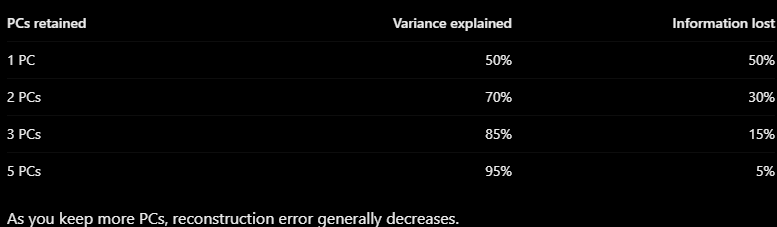


- Step Details & Formulations
    * Data Standardization:
        * Scales each feature using `StandardScaler` (subtracting the mean $\mu$ and dividing by standard deviation $\sigma$):
          $$\text{Standardized Value} = \frac{X - \mu}{\sigma}$$
        * Essential because features exist on different scales (e.g., age from 0–100 vs. tumor area from 0–1000). Standardization ensures all features contribute equally to the covariance matrix.
        * Data Centering: Standardizing automatically centers the data around zero mean.
    * Covariance Matrix Computation:
        * Computes an $N \times N$ matrix for $N$ features (e.g., $30 \times 30$ covariance matrix for 30 features).
        * Diagonal Elements: Represent the individual variances of each feature.
        * Off-Diagonal Elements: Represent the pairwise covariances between pairs of features (e.g., area vs. perimeter).
    * Eigen Decomposition:
        * Decomposes the covariance matrix into Eigenvalues and Eigenvectors.
        * Eigenvalues ($\lambda$): Quantify the magnitude of variance explained by each principal component.
        * Eigenvectors: Define the directional orientations (axes) of the principal components in high-dimensional space.
    * Sorting & Projection:
        * Sort Eigenvalues and their corresponding Eigenvectors in descending order.
        * Project the standardized input data onto the selected top $K$ eigenvector directions to form the new principal component features.

### 4. Criteria for Selecting the Number of Principal Components
- Cumulative Variance Criterion
    * Select the number of components required to retain a specific target threshold of total information (e.g., 80%, 90%, or 95% variance).
- Kaiser Criterion
    * Retain only components with an Eigenvalue $\ge 1.0$ ($\lambda \ge 1.0$).
- Scree Plot / Elbow Method
    * Plot component index against its Eigenvalue / explained variance.
    * Identify the "elbow" where incremental gains in explained variance begin to flatten out.

### 5. Case Study: Breast Cancer Wisconsin Dataset (Python Implementation)
- Dataset Overview
    * Sample Count: 569 total data samples.
    * Feature Count: 30 continuous features measuring 10 cell characteristics (e.g., radius, perimeter, area, texture, concavity, compactness) across 3 metrics per characteristic (Mean, Standard Error, Worst).
    * Target Classes: Binary classification—Malignant (1) vs. Benign (0).
- Exploratory Data Diagnostics
    * Scale Differences: Feature scales vary drastically (e.g., mean area ranges from 600–700 with large standard deviation, while texture values are small).
    * High Feature Correlation: 44 feature pairs exhibit a Pearson correlation coefficient $r > 0.8$ (e.g., radius, perimeter, and area show near-perfect positive correlation).

### 6. PCA Variance Distribution & Feature Loadings

| Component | Eigenvalue ($\lambda$) | Variance Explained | Cumulative Variance |
| :--- | :---: | :---: | :---: |
| **PC1** | 13.3 | 44.3% | 44.3% |
| **PC2** | 5.7 | 19.0% | 63.3% |
| **PC3** | ~2.8 | 9.4% | 72.7% |
| **PC4** | ~1.9 | 6.6% | 79.3% |
| **PC5** | ~1.7 | 5.5% | 84.8% |
| **PC6** | ~1.2 | 4.0% | 88.8% |

- Variance Thresholds
    * 2 Components (PC1 + PC2): Retains 63.3% of total dataset variance.
    * 80% Variance Threshold: Requires 4 to 5 components.
    * Kaiser Criterion ($\lambda \ge 1.0$): Retains 6 components, capturing ~89% of total variance.
- Feature Loadings (Component Contributions)
    * PC1 Loadings: Heavily driven by concavity metrics (mean concave points, mean concavity, perimeter, and compactness).
    * PC2 Loadings: Influenced by fractional dimension, mean radius, compactness error, and mean area.
    * Loadings Maps: Demonstrate whether a feature contributes positively or negatively to a given principal component vector.

### 7. Reconstruction Quality & Information Loss
- Reverse Transformation
    * Data can be transformed from principal component space back to the original 30-feature space.
- Reconstruction Error Metrics
    * 2 Components: Retains 63.3% variance $\rightarrow$ 36.7% reconstruction error / information loss.
    * 5 Components: Retains ~85% variance $\rightarrow$ 15.2% reconstruction error.
    * 10 Components: Retains ~95% variance $\rightarrow$ 4.8% reconstruction error.
- Sample-Level Variation
    * Reconstruction fidelity varies across individual data points (e.g., sample 0 shows low error with 10 components, whereas sample 150 exhibits higher residual error under 2 components).

### 8. Downstream Machine Learning Classification & Performance
- Workflow Best Practices
    1. Split raw data into Training and Testing sets before pre-processing.
    2. Fit `StandardScaler` on Training data only, then transform both Training and Test sets.
    3. Fit `PCA` on Training data only, then transform both Training and Test sets.
- Model Comparison on 2D PC Space (30 Features $\rightarrow$ 2 PCs = 15$\times$ Reduction)
    * K-Means Clustering (Unsupervised):
        * Creates a linear decision boundary between clusters.
        * Test Accuracy: 92.4% (11 misclassified test samples out of 143).
    * Support Vector Machine (SVM, Supervised):
        * Fits a curved / non-linear decision boundary.
        * Test Accuracy: 95.8% (~96%) (only 5 misclassified test samples out of 143).

### 9. Key Summary Takeaways

| Metric / Aspect | Raw Original Data | Post-PCA Data (2 PCs) |
| :--- | :--- | :--- |
| **Number of Features** | 30 features | 2 features (15$\times$ compression) |
| **Feature Correlation** | High ($44\text{ pairs with } r > 0.8$) | $0.0$ (Orthogonal / Uncorrelated) |
| **Total Variance Retained** | 100% | 63.3% |
| **K-Means Accuracy** | Baseline | 92.4% |
| **SVM Accuracy** | Baseline | 95.8% |

* for code -
    * https://github.com/bnsreenu/python_for_microscopists/blob/master/370_PCA_Dimensionality_Reduction.ipynb